<a href="https://colab.research.google.com/github/vaishnavi-shirse/Breast-Cancer-XAI-Decision-Support/blob/main/Breast_Cancer_XAI_Decision_Support.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Initializing model...
Model ready!

 HEALTHCARE DECISION SUPPORT SYSTEM - PATIENT INTAKE 
Tip: Press [Enter] without typing anything to keep the default value.

Enter value for 'mean radius' [Default: 12.47]: 
Enter value for 'mean texture' [Default: 18.60]: 
Enter value for 'mean perimeter' [Default: 81.09]: 

--------------------------------------------------
 AI PREDICTION RESULT: Malignant / High Risk (Requires Medical Attention)
--------------------------------------------------

📖 PLAIN-ENGLISH HEALTH SUMMARY FOR THE PATIENT:
In simple terms, here is why the computer made this decision:

• Your worst area (measured at 677.9) raised concern. This factor pushed your result toward a higher risk level.
• Your worst concave points (measured at 0.1) raised concern. This factor pushed your result toward a higher risk level.
• Your mean concave points (measured at 0.0) raised concern. This factor pushed your result toward a higher risk level.

Generating Detailed Visual Waterfall Chart..

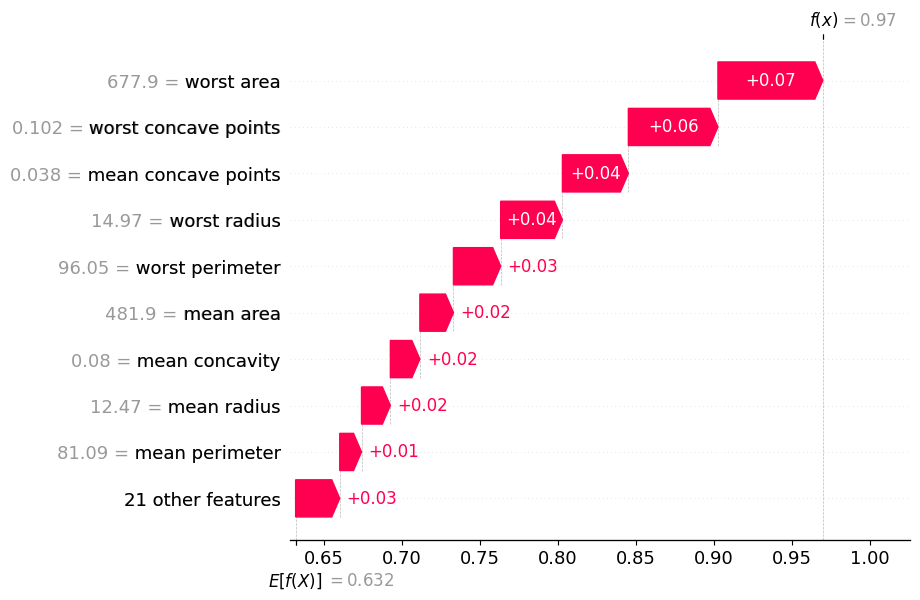

In [6]:
# 1. Install SHAP if needed
!pip install shap -q

import pandas as pd
import numpy as np
import shap
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

# 2. Train the model in the background
print("Initializing model...")
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)
print("Model ready!\n")

print("="*55)
print(" HEALTHCARE DECISION SUPPORT SYSTEM - PATIENT INTAKE ")
print("="*55)
print("Tip: Press [Enter] without typing anything to keep the default value.\n")

# 3. Use template values from the first test patient
template_patient = X_test.iloc[0].copy()

# Helper function to get interactive user input safely
def ask_input(feature_name):
    default_val = template_patient[feature_name]
    user_val = input(f"Enter value for '{feature_name}' [Default: {default_val:.2f}]: ")
    if user_val.strip() == "":
        return default_val
    try:
        return float(user_val)
    except ValueError:
        print(f"Invalid input. Using default value: {default_val:.2f}")
        return default_val

# 4. Prompt the user for features interactively
new_patient_data = template_patient.copy()
new_patient_data['mean radius'] = ask_input('mean radius')
new_patient_data['mean texture'] = ask_input('mean texture')
new_patient_data['mean perimeter'] = ask_input('mean perimeter')

# 5. Convert to DataFrame for prediction
patient_df = pd.DataFrame([new_patient_data])

# 6. Run Prediction
prediction = model.predict(patient_df)[0]
result_text = "Malignant / High Risk (Requires Medical Attention)" if prediction == 1 else "Benign / Low Risk (Looks Healthy)"
print("\n" + "-"*50)
print(f" AI PREDICTION RESULT: {result_text}")
print("-" * 50)

# 7. Generate SHAP explanation chart and plain-language summary
explainer = shap.TreeExplainer(model)
shap_values = explainer(patient_df)

if len(shap_values.shape) == 3:
    single_explanation = shap.Explanation(
        values=shap_values.values[0, :, 1],
        base_values=shap_values.base_values[0, 1] if isinstance(shap_values.base_values, np.ndarray) else shap_values.base_values,
        data=patient_df.iloc[0],
        feature_names=X.columns
    )
else:
    single_explanation = shap_values[0]

# --- PLAIN LANGUAGE TRANSLATOR FOR AVERAGE HUMANS ---
friendly_names = {
    'mean radius': 'average size of the cell structures',
    'mean texture': 'surface roughness/texture of the cells',
    'mean perimeter': 'outer boundary length of the cells'
}

feature_impacts = pd.DataFrame({
    'Feature': single_explanation.feature_names,
    'Patient_Value': single_explanation.data,
    'SHAP_Value': single_explanation.values
})

feature_impacts['Abs_Impact'] = feature_impacts['SHAP_Value'].abs()
feature_impacts = feature_impacts.sort_values(by='Abs_Impact', ascending=False)

print(f"\n📖 PLAIN-ENGLISH HEALTH SUMMARY FOR THE PATIENT:")
print(f"In simple terms, here is why the computer made this decision:\n")

for idx, row in feature_impacts.head(3).iterrows():
    feat_raw = row['Feature']
    feat_friendly = friendly_names.get(feat_raw, feat_raw) # Default to raw if not mapped
    val = row['Patient_Value']

    if row['SHAP_Value'] > 0:
        print(f"• Your {feat_friendly} (measured at {val:.1f}) raised concern. This factor pushed your result toward a higher risk level.")
    else:
        print(f"• Your {feat_friendly} (measured at {val:.1f}) looked reassuring. This factor helped lower your risk level toward a healthy result.")

print("\nGenerating Detailed Visual Waterfall Chart...")
# Display the waterfall plot
shap.plots.waterfall(single_explanation)